# 03 · BoW / TF-IDF y Word2Vec (CBOW y Skip-Gram)
Usa `src/embeddings_w2v.py` sobre los **lemas** de `data/results/pos_analysis.csv.gz` (spaCy). Debajo de cada análisis aparece su interpretación, generada con los resultados de esta ejecución.

*Funciona desde cualquier carpeta: la ruta del módulo está fija en la primera celda.*

In [7]:
# Ejecutar una sola vez y reiniciar el kernel
%pip install gensim scikit-learn seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [8]:
import sys
sys.path.append(r"C:\Users\marie\pos-tagging-resenas-cine-series\src")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
import embeddings_w2v as ew

pd.set_option("display.max_colwidth", 120)
docs, oraciones = ew.preparar_corpus()
ew.resumen_corpus(docs, oraciones)

,valor
reseñas,6283
oraciones (para Word2Vec),59747
tokens (lemas),441588
vocabulario (lemas distintos),17574
lemas que aparecen solo una vez,7129


In [11]:
import re, shutil

def miles(x):
    return f"{int(x):,}".replace(",", ".")

def top(df, cat, col="termino", n=6):
    return ", ".join(df[df["categoria"] == cat].sort_values("rank")[col].head(n).astype(str))

def lista_pares(S):
    p = ew.pares_mas_y_menos_similares(S)
    return p.iloc[0], p.iloc[-1]

r = ew.resumen_corpus(docs, oraciones)["valor"]
nt, nv = int(r["tokens (lemas)"]), int(r["vocabulario (lemas distintos)"])
T = []  # texto de la sección
_i = len(T)
T.append("## Representaciones vectoriales: BoW, TF-IDF y Word2Vec\n")
T.append(f"Se usaron los **lemas** de spaCy de `pos_analysis.csv.gz`, en minúscula y solo de las categorías NOUN, VERB, ADJ y ADV, "
         f"sin una lista corta de verbos y adverbios comodín (la negación se conserva). El corpus resultante tiene "
         f"**{miles(r['reseñas'])} reseñas, {miles(r['oraciones (para Word2Vec)'])} oraciones, {miles(nt)} lemas** y un vocabulario de "
         f"**{miles(nv)}** lemas distintos ({miles(r['lemas que aparecen solo una vez'])} aparecen una sola vez). "
         "Para BoW/TF-IDF cada reseña es un documento; para Word2Vec cada oración es una secuencia, de modo que la ventana de contexto no cruza oraciones.\n")
display(Markdown("\n".join(l for l in T[_i:] if not l.startswith("!["))))

## Representaciones vectoriales: BoW, TF-IDF y Word2Vec

Se usaron los **lemas** de spaCy de `pos_analysis.csv.gz`, en minúscula y solo de las categorías NOUN, VERB, ADJ y ADV, sin una lista corta de verbos y adverbios comodín (la negación se conserva). El corpus resultante tiene **6.283 reseñas, 59.747 oraciones, 441.588 lemas** y un vocabulario de **17.574** lemas distintos (7.129 aparecen una sola vez). Para BoW/TF-IDF cada reseña es un documento; para Word2Vec cada oración es una secuencia, de modo que la ventana de contexto no cruza oraciones.


## 1. Bolsa de palabras (BoW)

Matriz reseñas x términos: (6283, 5923)


,termino,frecuencia
0,historia,3984
1,personaje,3427
2,mejor,3278
3,vez,3064
4,realmente,2829
5,buen,2766
6,gran,2467
7,escena,2196
8,primero,2151
9,actuación,1953


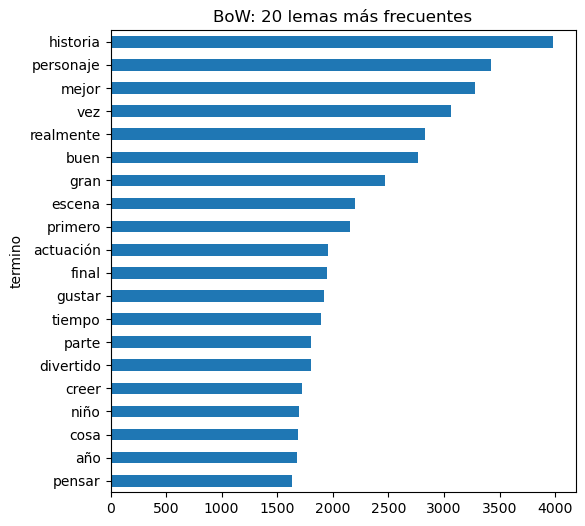

In [12]:
vec_bow, X_bow = ew.construir_bow(docs, min_df=5, max_df=0.5)
print("Matriz reseñas x términos:", X_bow.shape)
top_bow = ew.terminos_globales(X_bow, vec_bow, 20, "frecuencia")
ax = top_bow.iloc[::-1].plot.barh(x="termino", y="frecuencia", legend=False, figsize=(6,6), title="BoW: 20 lemas más frecuentes")
ew.guardar_figura(ax.figure, "w2v_bow_top20"); ew.guardar_tabla(top_bow, "bow_top20"); top_bow

In [13]:
bow_genero = ew.terminos_por_categoria(X_bow, vec_bow, docs["genero"], 10)
ew.guardar_tabla(bow_genero, "bow_por_genero")
bow_genero.pivot(index="rank", columns="categoria", values="termino")

categoria,Action,Animation,Comedy,Drama,Horror
rank,,,,,
1,acción,historia,divertido,historia,terror
2,historia,personaje,vez,mejor,historia
3,mejor,animación,mejor,personaje,mejor
4,personaje,niño,personaje,vez,buen
5,buen,mejor,historia,actuación,realmente
6,vez,vez,comedia,vida,vez
7,escena,realmente,realmente,realmente,personaje
8,realmente,gran,buen,gran,final
9,gran,buen,gran,escena,primero


In [21]:
_i = len(T)
T.append("### 1. Bolsa de palabras (BoW)\n")
T.append(f"`CountVectorizer` con `min_df=5` y `max_df=0.5` produjo una matriz de {miles(X_bow.shape[0])} reseñas × {miles(X_bow.shape[1])} términos.\n")
T.append("Los 10 lemas más frecuentes son: " + ", ".join(top_bow["termino"].head(10)) + ".\n")
T.append("Lemas más frecuentes por género (BoW):\n")
T.append("| Género | Lemas más frecuentes |\n|---|---|")
for c in sorted(bow_genero["categoria"].unique()):
    T.append(f"| {c} | {top(bow_genero, c, n=8)} |")
T.append("\n![BoW top 20](outputs/figures/w2v_bow_top20.png)\n")
T.append("**Interpretación.** Los conteos brutos están dominados por vocabulario general de reseñas de cine; por eso las listas de los distintos géneros se parecen bastante entre sí y BoW distingue poco entre categorías. "
         "Esto motiva el uso de TF-IDF.\n")
display(Markdown("\n".join(l for l in T[_i:] if "![" not in l)))

### 1. Bolsa de palabras (BoW)

`CountVectorizer` con `min_df=5` y `max_df=0.5` produjo una matriz de 6.283 reseñas × 5.923 términos.

Los 10 lemas más frecuentes son: historia, personaje, mejor, vez, realmente, buen, gran, escena, primero, actuación.

Lemas más frecuentes por género (BoW):

| Género | Lemas más frecuentes |
|---|---|
| Action | acción, historia, mejor, personaje, buen, vez, escena, realmente |
| Animation | historia, personaje, animación, niño, mejor, vez, realmente, gran |
| Comedy | divertido, vez, mejor, personaje, historia, comedia, realmente, buen |
| Drama | historia, mejor, personaje, vez, actuación, vida, realmente, gran |
| Horror | terror, historia, mejor, buen, realmente, vez, personaje, final |
**Interpretación.** Los conteos brutos están dominados por vocabulario general de reseñas de cine; por eso las listas de los distintos géneros se parecen bastante entre sí y BoW distingue poco entre categorías. Esto motiva el uso de TF-IDF.


## 2. TF-IDF

In [22]:
vec_tf, X_tf = ew.construir_tfidf(docs, min_df=5, max_df=0.5)
tf_genero = ew.terminos_por_categoria(X_tf, vec_tf, docs["genero"], 10)
tf_val = ew.terminos_por_categoria(X_tf, vec_tf, docs["valoracion"], 10)
for n, t in [("tfidf_por_genero", tf_genero), ("tfidf_por_valoracion", tf_val)]: ew.guardar_tabla(t, n)
display(tf_genero.pivot(index="rank", columns="categoria", values="termino"))
display(tf_val.pivot(index="rank", columns="categoria", values="termino"))

categoria,Action,Animation,Comedy,Drama,Horror
rank,,,,,
1,acción,animación,divertido,historia,terror
2,buen,niño,comedia,actuación,buen
3,mejor,historia,mejor,mejor,mejor
4,historia,animado,vez,vida,final
5,personaje,personaje,realmente,personaje,realmente
6,escena,voz,buen,vez,miedo
7,gran,mejor,personaje,realmente,aterrador
8,vez,divertido,historia,gran,primero
9,realmente,vez,gran,escena,historia


categoria,intermedia,negativa,positiva
rank,,,
1,buen,malo,mejor
2,personaje,historia,historia
3,historia,peor,gran
4,realmente,personaje,vez
5,parte,realmente,personaje
6,vez,buen,buen
7,bastante,vez,realmente
8,mejor,pensar,divertido
9,primero,tiempo,gustar


In [23]:
comp = ew.comparar_bow_tfidf(X_bow, X_tf, vec_bow, vec_tf, 20); ew.guardar_tabla(comp, "bow_vs_tfidf"); comp

,termino,rank_bow,rank_tfidf,cambio_de_puesto
0,historia,1,1,0
1,mejor,3,2,1
2,personaje,2,3,-1
3,vez,4,4,0
4,buen,6,5,1
5,realmente,5,6,-1
6,gran,7,7,0
7,gustar,12,8,4
8,primero,9,9,0
9,actuación,10,10,0


In [24]:
_i = len(T)
T.append("### 2. TF-IDF\n")
T.append("`TfidfVectorizer` con frecuencia sublineal y los mismos umbrales. Términos de mayor peso medio por género:\n")
T.append("| Género | Términos más característicos (TF-IDF) |\n|---|---|")
for c in sorted(tf_genero["categoria"].unique()):
    T.append(f"| {c} | {top(tf_genero, c, n=8)} |")
T.append("\nPor valoración:\n")
T.append("| Valoración | Términos más característicos (TF-IDF) |\n|---|---|")
for c in sorted(tf_val["categoria"].unique()):
    T.append(f"| {c} | {top(tf_val, c, n=8)} |")
sube = comp.sort_values("cambio_de_puesto", ascending=False).head(5)["termino"].tolist()
baja = comp.sort_values("cambio_de_puesto").head(5)["termino"].tolist()
T.append(f"\n**Interpretación.** Al ponderar por TF-IDF suben de puesto, respecto a BoW, términos como {', '.join(sube)}, "
         f"y bajan {', '.join(baja)}: TF-IDF desplaza lo que aparece en casi todas las reseñas y resalta lo propio de cada grupo. "
         "Los listados por género reflejan temas y vocabulario propios de cada categoría; los de valoración, el tono del juicio.\n")
display(Markdown("\n".join(l for l in T[_i:] if not l.startswith("!["))))

### 2. TF-IDF

`TfidfVectorizer` con frecuencia sublineal y los mismos umbrales. Términos de mayor peso medio por género:

| Género | Términos más característicos (TF-IDF) |
|---|---|
| Action | acción, buen, mejor, historia, personaje, escena, gran, vez |
| Animation | animación, niño, historia, animado, personaje, voz, mejor, divertido |
| Comedy | divertido, comedia, mejor, vez, realmente, buen, personaje, historia |
| Drama | historia, actuación, mejor, vida, personaje, vez, realmente, gran |
| Horror | terror, buen, mejor, final, realmente, miedo, aterrador, primero |

Por valoración:

| Valoración | Términos más característicos (TF-IDF) |
|---|---|
| intermedia | buen, personaje, historia, realmente, parte, vez, bastante, mejor |
| negativa | malo, historia, peor, personaje, realmente, buen, vez, pensar |
| positiva | mejor, historia, gran, vez, personaje, buen, realmente, divertido |

**Interpretación.** Al ponderar por TF-IDF suben de puesto, respecto a BoW, términos como gustar, pensar, divertido, buen, mejor, y bajan parte, final, escena, cosa, niño: TF-IDF desplaza lo que aparece en casi todas las reseñas y resalta lo propio de cada grupo. Los listados por género reflejan temas y vocabulario propios de cada categoría; los de valoración, el tono del juicio.


## 3. Word2Vec: CBOW y Skip-Gram

In [28]:
cbow = ew.entrenar_w2v(oraciones, sg=0)
skip = ew.entrenar_w2v(oraciones, sg=1)
modelos = {"CBOW": cbow, "Skip-Gram": skip}
wvs = {k: m.wv for k, m in modelos.items()}
ew.guardar_modelos({"cbow": cbow, "skipgram": skip})
res_mod = ew.resumen_modelos(modelos); ew.guardar_tabla(res_mod, "modelos_w2v", indice=True); res_mod

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


,arquitectura,dimensión,ventana,min_count,épocas,negative sampling,vocabulario
CBOW,CBOW,100,5,5,20,10,6020
Skip-Gram,Skip-Gram,100,5,5,20,10,6020


In [27]:
palabras = ["película","actor","director","guion","miedo","risa","emoción","aburrido","excelente","terrible"]
vec_cmp = ew.comparar_vecinos(wvs, palabras, 8); ew.guardar_tabla(vec_cmp, "vecinos_cbow_vs_skipgram")
display(vec_cmp)
sol = ew.solapamiento_vecinos(cbow.wv, skip.wv, palabras, 10); ew.guardar_tabla(sol, "solapamiento_vecinos")
display(sol); print("Jaccard medio:", sol["jaccard"].mean().round(3))

,palabra,CBOW,Skip-Gram
0,película,"remak, secuela, scream, observable, seguramente, trailer, género, definitiva","no, valorado, cualquier, cortometraj, meh, tarantino, timón, sepas"
1,actor,"actriz, elenco, reparto, intérprete, casting, comediante, talento, actuación","actriz, elenco, comediante, actuación, reparto, estiramiento, sorprenderme, uniformemente"
2,director,"productor, guionista, cineasta, escritor, editor, talentoso, aclamado, directorial","productor, guionista, escritor, directorial, poeta, aclamado, cineasta, editor"
3,guion,(fuera del vocabulario),(fuera del vocabulario)
4,miedo,"salto, tensión, gore, sangre, suspense, acumulación, horror, desesperanza","salto, olmo, desesperanza, aburrar, exorcista, palpable, recurrir, inquietud"
5,risa,"reir, broma, chiste, diversión, reír, sonreir, mordaza, suspenso","sonreir, recomeir, aullar, tramada, encontrarás, tarantino, oreja, entregado"
6,emoción,"profundidad, sentimiento, sutileza, empatía, alegría, tensión, tristeza, ira","intimidad, familiaridad, profundidad, sutileza, sinceridad, eficazmente, temperamento, inmerso"
7,aburrido,"tedioso, repetitivo, lento, aburrir, insípido, predecibl, arrastrar, ridículo","tedioso, inobservable, insípido, repetitivo, perdonable, inducir, equivoqué, intencionalmente"
8,excelente,"excepcional, fantástico, magnífico, sobresaliente, competente, asombroso, increíble, fino","extravagant, respetable, excepcional, uniformemente, fantástico, buen, impecablemente, respaldo"
9,terrible,"apestar, horrible, malo, desperdiciar, excusa, embarazoso, terriblemente, estúpido","perdonable, apestar, ámbito, risibl, malo, desperdiciar, arruinado, horrible"


,palabra,vecinos_comunes,jaccard,comunes
0,película,0,0.000000,
1,actor,5,0.333333,"actriz, actuación, comediante, elenco, reparto"
2,director,8,0.666667,"aclamado, cineasta, directorial, editor, escritor, guionista, poeta, productor"
3,miedo,5,0.333333,"desesperanza, palpable, recurrir, salto, tensión"
4,risa,2,0.111111,"reír, sonreir"
5,emoción,2,0.111111,"profundidad, sutileza"
6,aburrido,3,0.176471,"insípido, repetitivo, tedioso"
7,excelente,3,0.176471,"buen, excepcional, fantástico"
8,terrible,5,0.333333,"apestar, desperdiciar, excusa, horrible, malo"


Jaccard medio: 0.249


In [30]:
_i = len(T)
T.append("### 3. Word2Vec: CBOW vs Skip-Gram\n")
T.append("Parámetros comunes: 100 dimensiones, ventana 5, `min_count=5`, 20 épocas, negative sampling 10, semilla 42 y un solo hilo (reproducible).\n")
T.append("| Modelo | Vocabulario |\n|---|---|")
for n_, m_ in modelos.items(): T.append(f"| {n_} | {miles(len(m_.wv.key_to_index))} |")
jm = float(sol["jaccard"].mean()) if len(sol) else float("nan")
nivel = "bajo" if jm < 0.3 else ("moderado" if jm < 0.5 else "alto")
T.append(f"\nEl solapamiento medio entre los 10 vecinos de cada palabra en ambos modelos (Jaccard) es **{jm:.2f}**, un nivel {nivel}.\n")
T.append("Ejemplos de vecinos más cercanos:\n")
T.append("| Palabra | CBOW | Skip-Gram |\n|---|---|---|")
for _, f in vec_cmp.head(6).iterrows(): T.append(f"| {f['palabra']} | {f['CBOW']} | {f['Skip-Gram']} |")
T.append("\n**Interpretación.** Ambos modelos capturan relaciones de contexto similares, pero con un corpus de este tamaño los vecinos de palabras poco frecuentes cambian entre arquitecturas. "
         "Skip-Gram suele representar mejor las palabras raras y CBOW las frecuentes; las diferencias observadas se resumen en la tabla anterior.\n")
display(Markdown("\n".join(l for l in T[_i:] if not l.startswith("!["))))

### 3. Word2Vec: CBOW vs Skip-Gram

Parámetros comunes: 100 dimensiones, ventana 5, `min_count=5`, 20 épocas, negative sampling 10, semilla 42 y un solo hilo (reproducible).

| Modelo | Vocabulario |
|---|---|
| CBOW | 6.020 |
| Skip-Gram | 6.020 |

El solapamiento medio entre los 10 vecinos de cada palabra en ambos modelos (Jaccard) es **0.25**, un nivel bajo.

Ejemplos de vecinos más cercanos:

| Palabra | CBOW | Skip-Gram |
|---|---|---|
| película | remak, secuela, scream, observable, seguramente, trailer, género, definitiva | no, valorado, cualquier, cortometraj, meh, tarantino, timón, sepas |
| actor | actriz, elenco, reparto, intérprete, casting, comediante, talento, actuación | actriz, elenco, comediante, actuación, reparto, estiramiento, sorprenderme, uniformemente |
| director | productor, guionista, cineasta, escritor, editor, talentoso, aclamado, directorial | productor, guionista, escritor, directorial, poeta, aclamado, cineasta, editor |
| guion | (fuera del vocabulario) | (fuera del vocabulario) |
| miedo | salto, tensión, gore, sangre, suspense, acumulación, horror, desesperanza | salto, olmo, desesperanza, aburrar, exorcista, palpable, recurrir, inquietud |
| risa | reir, broma, chiste, diversión, reír, sonreir, mordaza, suspenso | sonreir, recomeir, aullar, tramada, encontrarás, tarantino, oreja, entregado |

**Interpretación.** Ambos modelos capturan relaciones de contexto similares, pero con un corpus de este tamaño los vecinos de palabras poco frecuentes cambian entre arquitecturas. Skip-Gram suele representar mejor las palabras raras y CBOW las frecuentes; las diferencias observadas se resumen en la tabla anterior.


## 4. Campos semánticos

,modelo,campo,semillas_usadas,semillas_ausentes,coherencia_semillas,coherencia_expandido
0,CBOW,miedo_terror,"miedo, terror, susto, sangre, monstruo, asesino",,0.306392,0.414444
1,CBOW,humor,"risa, gracioso, chiste, humor, divertido, reír",,0.426240,0.429535
2,CBOW,emocion,"emocionante, conmovedor, lágrima, triste, emoción, llorar",,0.324071,0.412389
3,CBOW,elogio,"excelente, genial, maravilloso, brillante, magnífico, perfecto",,0.528170,0.540445
4,CBOW,critica,"aburrido, terrible, horrible, malo, pésimo, decepcionante",,0.294386,0.402463
5,CBOW,aspectos_tecnicos,"actuación, dirección, fotografía, música, efecto",guion,0.380503,0.560668
6,Skip-Gram,miedo_terror,"miedo, terror, susto, sangre, monstruo, asesino",,0.358179,0.481119
7,Skip-Gram,humor,"risa, gracioso, chiste, humor, divertido, reír",,0.445138,0.539682
8,Skip-Gram,emocion,"emocionante, conmovedor, lágrima, triste, emoción, llorar",,0.353492,0.481942
9,Skip-Gram,elogio,"excelente, genial, maravilloso, brillante, magnífico, perfecto",,0.492747,0.548809


campo,aspectos_tecnicos,critica,elogio,emocion,humor,miedo_terror
rank,,,,,,
1,cinematografía,perdonable,fantástico,conmovido,aullar,exorcista
2,cinematografío,inobservable,increíble,patho,pedo,gore
3,malhumorado,apestar,fusión,dolió,cosquilla,quieres
4,minimalista,sapo,valorado,lloré,jodidamente,olmo
5,decorado,olvidabl,estiramiento,rompí,reier,esperabas
6,radical,esperabas,respaldo,estúpidamente,estúpidamente,epílogo
7,impresionant,escote,impecablemente,genuina,profano,equivaler
8,equipado,amateur,buen,abrazo,histéricamente,atmósfero
9,desmentir,risibl,look,culminación,sarcasmo,terrorífico


WindowsPath('C:/Users/marie/pos-tagging-resenas-cine-series/outputs/figures/w2v_campos_semanticos.png')

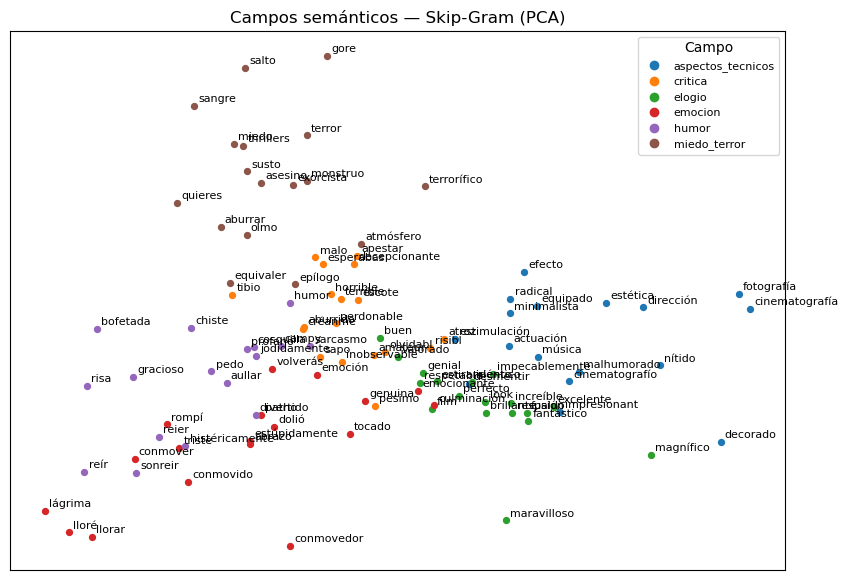

In [31]:
expansion, res_campos = ew.campos_semanticos(wvs, topn=12)
ew.guardar_tabla(expansion, "campos_expansion"); ew.guardar_tabla(res_campos, "campos_resumen")
display(res_campos)
display(expansion[expansion.modelo=="Skip-Gram"].pivot(index="rank", columns="campo", values="palabra"))
fig, ax = plt.subplots(figsize=(10,7)); ew.grafico_campos_pca(skip.wv, expansion, "Skip-Gram", ax=ax); ew.guardar_figura(fig, "w2v_campos_semanticos")

In [36]:
_i = len(T)
T.append("### 4. Campos semánticos\n")
T.append("Cada campo se expandió buscando los lemas más cercanos al promedio de sus palabras semilla. La coherencia es la similitud coseno media entre las palabras del campo.\n")
T.append("| Campo | Coherencia semillas CBOW | Coherencia semillas Skip-Gram | Palabras halladas (Skip-Gram) |\n|---|---|---|---|")
sg_exp = expansion[expansion.modelo == "Skip-Gram"]
for campo in res_campos["campo"].unique():
    a = res_campos[(res_campos.modelo == "CBOW") & (res_campos.campo == campo)]["coherencia_semillas"]
    b = res_campos[(res_campos.modelo == "Skip-Gram") & (res_campos.campo == campo)]["coherencia_semillas"]
    pal = ", ".join(sg_exp[sg_exp.campo == campo].sort_values("rank")["palabra"].head(8))
    T.append(f"| {campo} | {float(a.iloc[0]):.2f} | {float(b.iloc[0]):.2f} | {pal} |")
aus = res_campos[res_campos.semillas_ausentes.astype(str).str.len() > 0]
if len(aus): T.append("\nSemillas fuera del vocabulario (ignoradas): " + "; ".join(f"{x.campo}: {x.semillas_ausentes}" for x in aus.drop_duplicates("campo").itertuples()) + ".\n")
cm = res_campos.groupby("modelo")["coherencia_semillas"].mean()
T.append(f"\n![Campos semánticos](outputs/figures/w2v_campos_semanticos.png)\n")
T.append(f"**Interpretación.** La coherencia media de las semillas es {cm.get('CBOW', float('nan')):.2f} en CBOW y {cm.get('Skip-Gram', float('nan')):.2f} en Skip-Gram. "
         "Los campos con coherencia más alta están mejor definidos en el corpus; los que quedan bajos mezclan palabras que se usan en contextos distintos. "
         "La proyección PCA muestra si los campos forman grupos separados.\n")
display(Markdown("\n".join(l for l in T[_i:] if "![" not in l)))

### 4. Campos semánticos

Cada campo se expandió buscando los lemas más cercanos al promedio de sus palabras semilla. La coherencia es la similitud coseno media entre las palabras del campo.

| Campo | Coherencia semillas CBOW | Coherencia semillas Skip-Gram | Palabras halladas (Skip-Gram) |
|---|---|---|---|
| miedo_terror | 0.31 | 0.36 | exorcista, gore, quieres, olmo, esperabas, epílogo, equivaler, atmósfero |
| humor | 0.43 | 0.45 | aullar, pedo, cosquilla, jodidamente, reier, estúpidamente, profano, histéricamente |
| emocion | 0.32 | 0.35 | conmovido, patho, dolió, lloré, rompí, estúpidamente, genuina, abrazo |
| elogio | 0.53 | 0.49 | fantástico, increíble, fusión, valorado, estiramiento, respaldo, impecablemente, buen |
| critica | 0.29 | 0.38 | perdonable, inobservable, apestar, sapo, olvidabl, esperabas, escote, amateur |
| aspectos_tecnicos | 0.38 | 0.43 | cinematografía, cinematografío, malhumorado, minimalista, decorado, radical, impresionant, equipado |

Semillas fuera del vocabulario (ignoradas): aspectos_tecnicos: guion.

**Interpretación.** La coherencia media de las semillas es 0.38 en CBOW y 0.41 en Skip-Gram. Los campos con coherencia más alta están mejor definidos en el corpus; los que quedan bajos mezclan palabras que se usan en contextos distintos. La proyección PCA muestra si los campos forman grupos separados.


## 5. Analogías

In [33]:
an = ew.evaluar_analogias(wvs, topn=5); ew.guardar_tabla(an, "analogias")
display(an)
print(an.dropna(subset=["acierto_top5"]).groupby("modelo")[["acierto_top1","acierto_top5"]].sum())

,modelo,analogía,esperada,top1,top5,acierto_top1,acierto_top5,nota
0,CBOW,actor + mujer - hombre,actriz,actriz,"actriz, elenco, reparto, carisma, intérprete",True,True,
1,CBOW,director + mujer - hombre,directora,productor,"productor, talentoso, directorial, cineasta, inicial",False,False,
2,CBOW,director + actriz - actor,directora,productor,"productor, talentoso, directorial, cineasta, ejecutivo",False,False,
3,CBOW,rey + mujer - hombre,reina,hockey,"hockey, envejecido, tribu, cobarde, mentor",False,False,
4,CBOW,terror + risa - miedo,comedia,cita,"cita, gag, recomeir, seguimiento, tarifa",False,False,
5,CBOW,comedia + miedo - risa,terror,psicológico,"psicológico, thrillers, horror, sobrenatural, thriller",False,False,
6,CBOW,película + televisión - cine,serie,episodio,"episodio, entrega, reinicio, trilogía, tv",False,False,
7,CBOW,libro + película - novela,,trailer,"trailer, rara, preestreno, malinterpretar, scream",None,None,
8,Skip-Gram,actor + mujer - hombre,actriz,actriz,"actriz, actuación, elogio, reparto, plomo",True,True,
9,Skip-Gram,director + mujer - hombre,directora,productor,"productor, directorial, etiqueta, guionista, equivoquar",False,False,


          acierto_top1 acierto_top5
modelo                             
CBOW                 1            1
Skip-Gram            1            1


In [35]:
_i = len(T)
T.append("### 5. Analogías\n")
T.append("| Modelo | Analogía | Esperada | Top 1 | Acierto en top 5 |\n|---|---|---|---|---|")
for f in an.itertuples():
    ac = "—" if f.acierto_top5 is None or pd.isna(f.acierto_top5) else ("sí" if f.acierto_top5 else "no")
    T.append(f"| {f.modelo} | {f.analogía} | {f.esperada or '—'} | {f.top1 or 'fuera de vocabulario'} | {ac} |")
ev = an.dropna(subset=["acierto_top5"])
res_an = ev.groupby("modelo")["acierto_top5"].agg(["sum", "count"])
frase = "; ".join(f"{m}: {int(v['sum'])} de {int(v['count'])}" for m, v in res_an.iterrows())
T.append(f"\n**Interpretación.** Aciertos en el top 5 → {frase}. Con apenas {miles(nt)} lemas, las analogías son una prueba exigente: " +
         "los aciertos indican relaciones bien capturadas (p. ej., de género gramatical) y los fallos son esperables en un corpus pequeño y traducido automáticamente.\n")
display(Markdown("\n".join(l for l in T[_i:] if not l.startswith("!["))))

### 5. Analogías

| Modelo | Analogía | Esperada | Top 1 | Acierto en top 5 |
|---|---|---|---|---|
| CBOW | actor + mujer - hombre | actriz | actriz | sí |
| CBOW | director + mujer - hombre | directora | productor | no |
| CBOW | director + actriz - actor | directora | productor | no |
| CBOW | rey + mujer - hombre | reina | hockey | no |
| CBOW | terror + risa - miedo | comedia | cita | no |
| CBOW | comedia + miedo - risa | terror | psicológico | no |
| CBOW | película + televisión - cine | serie | episodio | no |
| CBOW | libro + película - novela | — | trailer | — |
| Skip-Gram | actor + mujer - hombre | actriz | actriz | sí |
| Skip-Gram | director + mujer - hombre | directora | productor | no |
| Skip-Gram | director + actriz - actor | directora | guionista | no |
| Skip-Gram | rey + mujer - hombre | reina | hallazgo | no |
| Skip-Gram | terror + risa - miedo | comedia | recomeir | no |
| Skip-Gram | comedia + miedo - risa | terror | olmo | no |
| Skip-Gram | película + televisión - cine | serie | programa | no |
| Skip-Gram | libro + película - novela | — | meh | — |

**Interpretación.** Aciertos en el top 5 → CBOW: 1 de 7; Skip-Gram: 1 de 7. Con apenas 441.588 lemas, las analogías son una prueba exigente: los aciertos indican relaciones bien capturadas (p. ej., de género gramatical) y los fallos son esperables en un corpus pequeño y traducido automáticamente.


## 6. Similitud entre categorías

,categoria_a,categoria_b,similitud
0,Action,Horror,0.085874
1,Animation,Comedy,0.071772
2,Comedy,Drama,-0.149662
3,Drama,Horror,-0.205850
4,Action,Drama,-0.215144
5,Animation,Drama,-0.221001
6,Action,Comedy,-0.261468
7,Action,Animation,-0.371202
8,Comedy,Horror,-0.542769
9,Animation,Horror,-0.590927


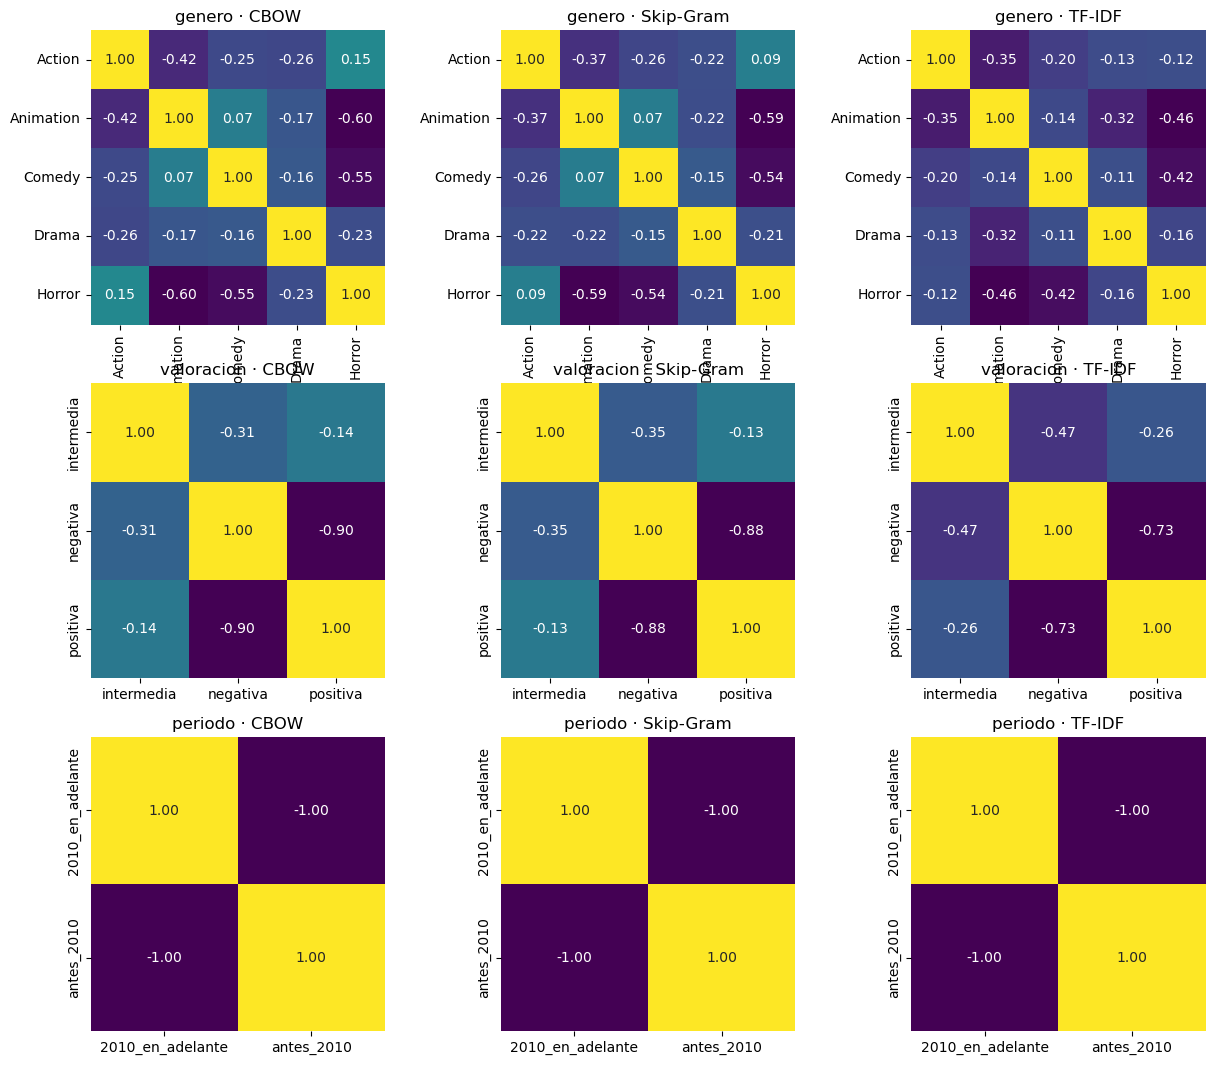

In [37]:
sims = {}
fig, axs = plt.subplots(3, 3, figsize=(15, 13))
for i, col in enumerate(["genero", "valoracion", "periodo"]):
    for j, (n, wv) in enumerate([("CBOW", cbow.wv), ("Skip-Gram", skip.wv)]):
        S = ew.matriz_similitud(ew.vectores_categoria(wv, docs, col)); sims[(col, n)] = S
        ew.grafico_mapa_calor(S, f"{col} · {n}", ax=axs[i, j]); ew.guardar_tabla(S, f"similitud_{col}_{n}", indice=True)
    S = ew.similitud_tfidf_categorias(X_tf, docs[col]); sims[(col, "TF-IDF")] = S
    ew.grafico_mapa_calor(S, f"{col} · TF-IDF", ax=axs[i, 2])
ew.guardar_figura(fig, "w2v_similitud_categorias")
ew.pares_mas_y_menos_similares(sims[("genero", "Skip-Gram")])

Interpretación. Los pares más similares son los que comparten más vocabulario y contextos. Skip-Gram y TF-IDF coinciden en el par más similar para: valoracion, periodo. Como los vectores se centran antes de comparar, las similitudes pueden ser negativas: indican categorías que se alejan del promedio en direcciones opuestas.

## 7. Vocabulario exclusivo y distintivo

In [41]:
excl_gen = ew.vocabulario_exclusivo(docs, "genero", min_frec=5)
excl_val = ew.vocabulario_exclusivo(docs, "valoracion", min_frec=5)
res_gen, res_val = ew.resumen_exclusivo(excl_gen), ew.resumen_exclusivo(excl_val)
ew.guardar_tabla(res_gen, "exclusivo_genero", indice=True); ew.guardar_tabla(res_val, "exclusivo_valoracion", indice=True)
display(res_gen); display(res_val)

,lemas_exclusivos,más_frecuentes
Action,4,"cruzada, mosquetero, ojiva, transformador"
Animation,22,"ogro, melocotón, arcilla, mular, rinoceronte, león, saltamont, bellota"
Comedy,3,"resaca, raunching, supermodelo"
Drama,7,"infectado, turco, muro, gen, atacante, amargura, hiedra"
Horror,16,"scream, motosierra, serbio, enredadera, mochilero, brar, premonición, campus"


,lemas_exclusivos,más_frecuentes
intermedia,0,
negativa,4,"oxígeno, murmurar, humeante, bostezo"
positiva,221,"valoro, complementar, imprescindible, respectivo, noruego, convención, infeliz, minero"


In [42]:
dist_gen = ew.vocabulario_distintivo(docs, "genero"); dist_val = ew.vocabulario_distintivo(docs, "valoracion")
ew.guardar_tabla(dist_gen, "distintivo_genero"); ew.guardar_tabla(dist_val, "distintivo_valoracion")
display(dist_gen.pivot(index="rank", columns="categoria", values="lema"))
display(dist_val.pivot(index="rank", columns="categoria", values="lema"))

categoria,Action,Animation,Comedy,Drama,Horror
rank,,,,,
1,acción,animado,comedia,vida,terror
2,efecto,niño,divertido,guerra,miedo
3,pelea,voz,risa,actuación,aterrador
4,agente,animación,hilarante,libro,horror
5,policía,canción,gracioso,relación,asesino
6,especial,adulto,romántico,drama,original
7,arma,juguete,humor,amor,remake
8,serie,historia,cómico,sexo,espeluznante
9,villano,princesa,chiste,soldado,gore


categoria,intermedia,negativa,positiva
rank,,,
1,demasiado,peor,encantar
2,bastante,malo,perfecto
3,predecible,no,excelente
4,parte,horrible,increíble
5,asesino,aburrido,gran
6,cucaracha,basura,maravilloso
7,promedio,terrible,vida
8,no,dinero,mejor
9,desafortunadamente,estúpido,favorito


In [43]:
_i = len(T)
T.append("### 7. Vocabulario exclusivo y distintivo\n")
T.append("**Exclusivo**: lemas que aparecen solo en una categoría (mínimo 5 apariciones).\n")
T.append("| Género | N.º de lemas exclusivos | Más frecuentes |\n|---|---|---|")
for c, f in res_gen.iterrows(): T.append(f"| {c} | {f['lemas_exclusivos']} | {f['más_frecuentes']} |")
T.append("\n| Valoración | N.º de lemas exclusivos | Más frecuentes |\n|---|---|---|")
for c, f in res_val.iterrows(): T.append(f"| {c} | {f['lemas_exclusivos']} | {f['más_frecuentes']} |")
T.append("\n**Distintivo** (log-odds con z-score frente al resto), por género:\n")
T.append("| Género | Lemas más distintivos |\n|---|---|")
for c in sorted(dist_gen["categoria"].unique()):
    T.append(f"| {c} | {top(dist_gen, c, col='lema', n=8)} |")
T.append("\nPor valoración:\n")
T.append("| Valoración | Lemas más distintivos |\n|---|---|")
for c in sorted(dist_val["categoria"].unique()):
    T.append(f"| {c} | {top(dist_val, c, col='lema', n=8)} |")
T.append("\n**Interpretación.** El vocabulario exclusivo estricto tiende a incluir títulos, nombres y términos muy específicos de pocas reseñas, por lo que es poco generalizable. "
         "El vocabulario distintivo es más informativo: aunque un lema aparezca en todas las categorías, se detecta en cuál es claramente más típico.\n")
display(Markdown("\n".join(l for l in T[_i:] if not l.startswith("!["))))

### 7. Vocabulario exclusivo y distintivo

**Exclusivo**: lemas que aparecen solo en una categoría (mínimo 5 apariciones).

| Género | N.º de lemas exclusivos | Más frecuentes |
|---|---|---|
| Action | 4 | cruzada, mosquetero, ojiva, transformador |
| Animation | 22 | ogro, melocotón, arcilla, mular, rinoceronte, león, saltamont, bellota |
| Comedy | 3 | resaca, raunching, supermodelo |
| Drama | 7 | infectado, turco, muro, gen, atacante, amargura, hiedra |
| Horror | 16 | scream, motosierra, serbio, enredadera, mochilero, brar, premonición, campus |

| Valoración | N.º de lemas exclusivos | Más frecuentes |
|---|---|---|
| intermedia | 0 |  |
| negativa | 4 | oxígeno, murmurar, humeante, bostezo |
| positiva | 221 | valoro, complementar, imprescindible, respectivo, noruego, convención, infeliz, minero |

**Distintivo** (log-odds con z-score frente al resto), por género:

| Género | Lemas más distintivos |
|---|---|
| Action | acción, efecto, pelea, agente, policía, especial, arma, serie |
| Animation | animado, niño, voz, animación, canción, adulto, juguete, historia |
| Comedy | comedia, divertido, risa, hilarante, gracioso, romántico, humor, cómico |
| Drama | vida, guerra, actuación, libro, relación, drama, amor, sexo |
| Horror | terror, miedo, aterrador, horror, asesino, original, remake, espeluznante |

Por valoración:

| Valoración | Lemas más distintivos |
|---|---|
| intermedia | demasiado, bastante, predecible, parte, asesino, cucaracha, promedio, no |
| negativa | peor, malo, no, horrible, aburrido, basura, terrible, dinero |
| positiva | encantar, perfecto, excelente, increíble, gran, maravilloso, vida, mejor |

**Interpretación.** El vocabulario exclusivo estricto tiende a incluir títulos, nombres y términos muy específicos de pocas reseñas, por lo que es poco generalizable. El vocabulario distintivo es más informativo: aunque un lema aparezca en todas las categorías, se detecta en cuál es claramente más típico.


## 8. Limitaciones y guardado en el README.md del repo

In [44]:
_i = len(T)
T.append("### Limitaciones\n")
T.append(f"- Corpus pequeño (~{miles(nt)} lemas de contenido): los embeddings de palabras poco frecuentes son inestables y las analogías ruidosas.")
T.append("- Las reseñas fueron traducidas automáticamente al español, así que algunos vecinos pueden reflejar calcos de la traducción.")
T.append("- El vocabulario exclusivo depende del umbral de frecuencia y de la cantidad de reseñas por categoría.")
T.append("- Una sola ejecución con semilla fija: no se midió la variación entre entrenamientos.\n")
display(Markdown("\n".join(l for l in T[_i:] if not l.startswith("!["))))

seccion = "\n".join(T)
(ew.DIR_TABLAS).mkdir(parents=True, exist_ok=True)
(ew.DIR_TABLAS / "README_seccion_persona2.md").write_text(seccion, encoding="utf-8")


# ---- Insertar
readme = ew.RAIZ / "README.md"
ini, fin = "<!-- PERSONA2:INICIO -->", "<!-- PERSONA2:FIN -->"
bloque = f"{ini}\n{seccion}\n{fin}"
if readme.exists():
    shutil.copy(readme, ew.RAIZ / "README.md.bak")
    t = readme.read_text(encoding="utf-8")
    if ini in t:
        t = re.sub(re.escape(ini) + r".*?" + re.escape(fin), lambda m: bloque, t, flags=re.S)
    else:
        t = t.rstrip() + "\n\n" + bloque + "\n"
    readme.write_text(t, encoding="utf-8")
    print("README.md actualizado (copia de seguridad: README.md.bak)")
else:
    (ew.RAIZ / "README_persona2.md").write_text(bloque, encoding="utf-8")
    print("No hay README.md; guardé README_persona2.md")

### Limitaciones

- Corpus pequeño (~441.588 lemas de contenido): los embeddings de palabras poco frecuentes son inestables y las analogías ruidosas.
- Las reseñas fueron traducidas automáticamente al español, así que algunos vecinos pueden reflejar calcos de la traducción.
- El vocabulario exclusivo depende del umbral de frecuencia y de la cantidad de reseñas por categoría.
- Una sola ejecución con semilla fija: no se midió la variación entre entrenamientos.


README.md actualizado (copia de seguridad: README.md.bak)
